# 8. Literatura y fundamento del diseño

La revisión relaciona el pronóstico diario de demanda con tres líneas de trabajo: redes numéricas, representaciones multiescala e integración de documentos. Se distinguen evidencia directa de demanda, estudios de precio eléctrico y métodos de otros dominios. El país de afiliación identifica a los autores; el territorio de los datos identifica el caso empírico. Los resultados conservan la métrica, unidad y configuración de cada publicación.

## 8.1. Fuentes, selección y alcance

La consolidación del 8 de noviembre de 2026 reúne 29 estudios destacados: seis textos completos sobre demanda y 23 estudios metodológicos y aplicados, de los cuales 11 se revisaron en texto completo y 12 mediante resumen. En paralelo, el registro de comparadores contiene 20 textos completos de precio y mercados relacionados. Estos conjuntos se solapan y sus tamaños no se suman como publicaciones únicas.

Las exportaciones disponibles contienen 615 registros de Scopus, 293 de Web of Science y 438 de IEEE Xplore. La exportación de Scopus supera en 53 registros el inventario inicial de 562; esa diferencia no se ha conciliado registro a registro. Las cadenas originales y las fechas de ejecución de las búsquedas institucionales no están conservadas. Los cinco archivos de IEEE se recibieron el 6 de noviembre de 2026; esa fecha no acredita cuándo se ejecutó cada consulta. La búsqueda pública dirigida está registrada el 3 de noviembre de 2026. No se presenta este inventario como una revisión sistemática completa ni como un diagrama PRISMA de registros únicos.

Se priorizaron pronóstico eléctrico, comparación explícita de arquitecturas, información documental y trazabilidad del resultado. Los avisos de retirada y retractación se separaron de la evidencia científica. La revisión y extracción cuentan con un solo revisor; no existe evaluación independiente duplicada.

### Protocolo de elegibilidad y alcance de la búsqueda

La ampliación dirigida de demanda considera publicaciones de 2018 al 8 de noviembre de 2026. Se incluyen estudios empíricos de demanda eléctrica con datos, horizonte y evaluación identificables, y métodos pertinentes para representación temporal o documental. Para contar comparadores se exige texto completo y evaluación explícita de una familia; las revisiones orientan contexto, los resúmenes generan candidatos y los modelos propuestos o componentes se excluyen del conteo. Se excluyen duplicados, retiradas, trabajos sin resultados verificables y aplicaciones sin vínculo metodológico justificado. País de afiliación y sistema eléctrico se registran por separado.

Las búsquedas públicas del 8 de noviembre de 2026 incluyeron: `(load forecasting OR electricity demand forecasting) AND (CNN OR convolutional OR LSTM OR MLP) AND (comparison OR benchmark)` y las consultas literales conservadas en el registro. No se dispone de las cadenas originales ni las fechas ejecutadas de Scopus y WoS; se mantienen como información no recuperada. Las decisiones actuales de elegibilidad no se presentan como un protocolo fechado antes de las búsquedas originales. El flujo entre bases sigue sin conciliación completa. [Registro de la ampliación pública](_static/literature/busqueda_demanda_20261108.json).

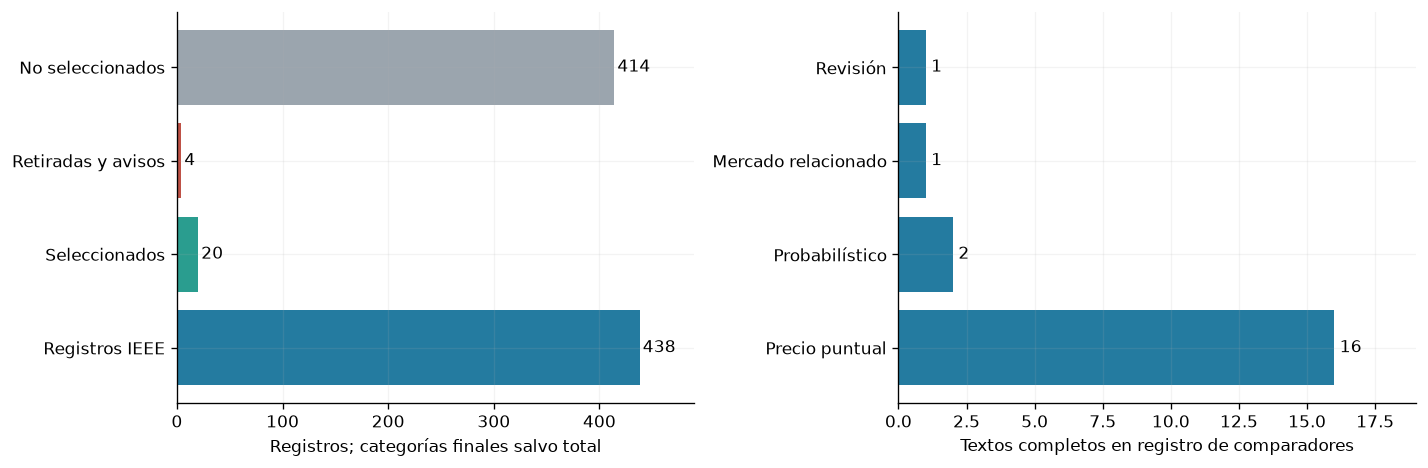

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'literature/analisis').is_dir())
D=ROOT/'literature/analisis'
plt.rcParams.update({'figure.dpi':120,'font.size':10})
estudios=pd.read_csv(D/'estudios_destacados.csv',keep_default_na=False)
comparadores=pd.read_csv(D/'estudios_comparadores.csv',keep_default_na=False)
extracciones=pd.read_csv(D/'extracciones_modelos.csv',keep_default_na=False)
recuperacion=pd.read_csv(D/'recuperacion.csv',keep_default_na=False)
ieee=pd.read_csv(D/'ieee_cribado.csv',keep_default_na=False)
seleccion=pd.read_csv(D/'ieee_seleccion.csv',keep_default_na=False)
assert estudios.study_id.is_unique and comparadores.study_id.is_unique
assert set(extracciones.study_id)<=set(comparadores.study_id)
manifest=json.loads((D/'manifiesto.json').read_text(encoding='utf-8'))
for item in manifest['archivos']:
    assert hashlib.sha256((D/item['archivo']).read_bytes()).hexdigest()==item['sha256']
fig,axes=plt.subplots(1,2,figsize=(12,4))
valores=[len(ieee),len(seleccion),4,len(ieee)-len(seleccion)-4]
axes[0].barh(['Registros IEEE','Seleccionados','Retiradas y avisos','No seleccionados'],valores,color=['#247ba0','#2a9d8f','#be5146','#9ba5ae'])
for i,v in enumerate(valores):axes[0].text(v+3,i,str(v),va='center')
axes[0].set_xlim(0,490);axes[0].set_xlabel('Registros; categorías finales salvo total')
counts=comparadores.estrato.value_counts().reindex(['puntual','probabilistico','mercado_relacionado','contexto_revision'])
axes[1].barh(['Precio puntual','Probabilístico','Mercado relacionado','Revisión'],counts,color='#247ba0')
for i,v in enumerate(counts):axes[1].text(v+.2,i,str(v),va='center')
axes[1].set_xlim(0,19);axes[1].set_xlabel('Textos completos en registro de comparadores')
fig.tight_layout();display(fig);plt.close(fig)

El cribado de IEEE retiene 20 de 438 registros: 12 prioritarios y ocho de contexto; cuatro corresponden a retiradas o avisos. El registro independiente de recuperación contiene 25 candidatos, con 20 textos completos y cinco pendientes. Dentro de los textos recuperados predominan los 16 estudios de precio puntual. La figura muestra dos inventarios con propósitos diferentes y no un flujo único de inclusión.

### Trazabilidad de la búsqueda

El registro de búsqueda pública conserva consultas sobre Time-MMD, la utilidad de modelos de lenguaje en pronóstico, NSW-EPNews y el benchmark de Lago et al. Las exportaciones institucionales permiten inspeccionar registros y decisiones, pero no reconstruir sus cadenas booleanas originales. Se identificaron 28 coincidencias de título de IEEE con el inventario inicial de 83; no se dispone de una conciliación completa entre las bases.

Los CSV de extracción preservan identificadores, roles de modelos, localizadores, fuentes y hashes de los textos revisados. El [registro de estudios de demanda](_static/literature/estudios_jbook.csv) y los [datos del análisis bibliográfico](_static/literature/estudios_destacados.csv) permiten inspeccionar la evidencia. Los archivos fuente de la revisión se distribuyen con el repositorio; los artículos completos permanecen en sus sitios de origen.

### Consultas públicas conservadas · 3 de noviembre de 2026

- Time MMD 2406.08627 full paper electricity multimodal dataset
- Are Language Models Actually Useful for Time Series Forecasting 2406.16964 pdf
- NSW-EPNews dataset electricity price news paper
- Lago De Ridder De Schutter 2021 forecasting day ahead electricity prices review open access benchmark arxiv 2008.08009

Estas consultas corresponden a una búsqueda dirigida de apoyo; no sustituyen las estrategias institucionales ausentes.

## 8.2. Estudios directamente relacionados con la demanda

| Estudio y fuente | Afiliación / datos | Modelo y diseño | Resultado e implicación |
|---|---|---|---|
| [Nti et al. (2020)](https://doi.org/10.1186/s43067-020-00021-8) | Ghana / múltiples países | Revisión de métodos, factores y escalas del pronóstico de carga. | Sustenta estudiar calendario, condiciones ambientales e historia de demanda; la heterogeneidad impide atribuir una arquitectura ganadora universal. |
| [Bai et al. (2024), News and Load](https://arxiv.org/abs/2301.07535v2) | Francia / Gran Bretaña e Irlanda del Norte | ExtraTrees con demanda, clima y calendario; incorporación de distintas representaciones de noticias. | Una representación por frecuencia de palabras reduce el MAE de 2374,07 a 2283,52 MW en su comparación. El resultado depende de representación y disponibilidad documental. |
| [Bai et al. (2023)](https://arxiv.org/abs/2309.06793) | Francia / Reino Unido | LSTM de 24 unidades y salida de 48 intervalos de media hora; compresión convolucional de embeddings de noticias. | Las variantes de texto presentan ganancias y deterioros frente a la LSTM numérica. El canal documental requiere selección y ablación controladas. |
| [Pelekis et al. (2023)](https://arxiv.org/abs/2302.12168v2) | Grecia / Portugal, 2013–2021 | MLP, LSTM, N-BEATS, TCN y TFT; 100 ensayos y ensamble mediano de 30 redes. Entrenamiento 2013–2019, validación 2020, prueba 2021. | N-BEATS alcanza MAPE 1,90 % en el caso univariado; con temperatura, MLP obtiene 1,92 %. La covariable no mejora a todas las familias. La temperatura evaluada ex post no demuestra disponibilidad operativa. |

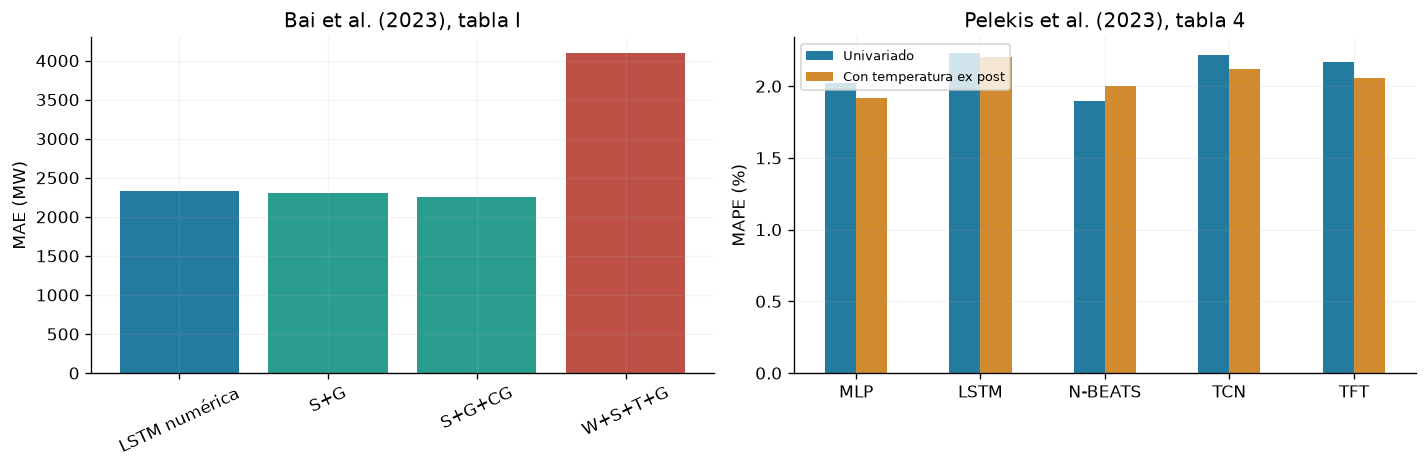

In [2]:
casos=pd.DataFrame({'variante':['LSTM numérica','S+G','S+G+CG','W+S+T+G'],'MAE_MW':[2333.20,2299.20,2248.55,4094.80]})
resultados=pd.DataFrame({'modelo':['MLP','LSTM','N-BEATS','TCN','TFT'],'Univariado':[2.02,2.23,1.90,2.22,2.17],'Con temperatura ex post':[1.92,2.20,2.00,2.12,2.06]})
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(casos.variante,casos.MAE_MW,color=['#247ba0','#2a9d8f','#2a9d8f','#be5146']);axes[0].tick_params(axis='x',rotation=25)
axes[0].set(ylabel='MAE (MW)',title='Bai et al. (2023), tabla I')
resultados.set_index('modelo').plot.bar(ax=axes[1],color=['#247ba0','#d18a2d'],rot=0)
axes[1].set(ylabel='MAPE (%)',xlabel='',title='Pelekis et al. (2023), tabla 4');axes[1].legend(fontsize=8)
fig.tight_layout();display(fig);plt.close(fig)
ganancia_bai=100*(1-casos.MAE_MW.iloc[2]/casos.MAE_MW.iloc[0])
deterioro_bai=100*(casos.MAE_MW.iloc[3]/casos.MAE_MW.iloc[0]-1)

En Bai et al., la mejor combinación de titulares S, descripciones G y descripciones corporativas CG reduce el MAE un 3.63 %, mientras que combinar palabras clave W, titulares S, textos T y descripciones G lo incrementa un 75.5 %. En Pelekis et al., añadir temperatura favorece a cuatro familias y perjudica a N-BEATS. Ambas comparaciones muestran que más información no garantiza menor error; las alturas de los dos paneles no son comparables porque corresponden a métricas y conjuntos diferentes.

### Comparadores adicionales de demanda revisados en texto completo

| Estudio | Afiliación / datos | Comparadores y resultados | Alcance crítico |
|---|---|---|---|
| [Kathirgamanathan et al. (2022), DOI 10.1049/tje2.12132](https://doi.org/10.1049/tje2.12132) | Canadá / Nueva Inglaterra, EE. UU. | ANN de dos capas, CNN1D y LSTM independientes; MAPE medio 4,137 %, 3,911 % y 3,894 %, respectivamente, tabla 7. | Ajuste 2004–2007, prueba 2009. Tabla 4 identifica CNN1D; la descripción de convoluciones no coincide completamente con esa tabla. El recorte de épocas de §8.3 limita comparación con la configuración completa. |
| [Laitsos et al. (2023), DOI 10.3390/math11132912](https://doi.org/10.3390/math11132912) | Grecia y EE. UU. / Thira, Grecia | MLP, LSTM, CNN1D, CNN-LSTM y TCN frente a ConvLSTM encoder–decoder. MAE 0,4477; 0,4275; 0,4936; 0,4412; 0,4576 y 0,4142 MW, tabla 4. | Datos horarios 2017–2019; últimos tres meses para prueba. Veinte iteraciones de optimización por modelo. No se acredita repetición multisemilla; el ajuste exclusivo del Min–Max en entrenamiento requiere verificación. |

Ambos estudios documentan CNN1D como comparador de demanda. Sus configuraciones y escalas difieren del SIN; respaldan la familia, sin transferir cifras ni demostrar que sea universalmente superior.

## 8.3. Síntesis de estudios complementarios

Se presentan las contribuciones, el país de afiliación y el caso empírico con su nivel de evidencia. «Texto completo» identifica resultados localizados en el documento; «Resumen» limita la conclusión a lo declarado en el resumen. NR indica información no reportada o no verificada. Los errores de distintos mercados, frecuencias y horizontes no forman un ranking común.

### Precio eléctrico

| Estudio y evidencia | Afiliación / caso | Arquitectura o contribución | Resultado |
|---|---|---|---|
| [Lago et al. (2018)](https://jesuslago.com/wp-content/uploads/Lago2018b.pdf) · Texto completo | Países Bajos; Bélgica / Bélgica · precio day-ahead | DNN, LSTM/GRU con capa densa y CNN de dos ramas | sMAPE: DNN 12,34 %; MLP de referencia 13,27 %. (§5.4 y tabla 7). |
| [Lago et al. (2021)](https://jesuslago.com/wp-content/uploads/1-s2.0-S0306261921004529-main-1.pdf) · Texto completo | Países Bajos; Polonia / Nord Pool, EE. UU., Bélgica, Francia y Alemania | Benchmark abierto DNN (dos capas ocultas) y LEAR | Nord Pool, MAE: DNN3 1,712; LEAR84 1,952 (escala del mercado). (§4.3 y tabla 2). |
| [Ugurlu et al. (2018)](https://mdpi-res.com/d_attachment/energies/energies-11-01255/article_deploy/energies-11-01255.pdf) · Texto completo | Turquía; Reino Unido / Turquía · precio day-ahead | GRU de tres capas; compara ANN, LSTM y CNN | Mejor MAE de GRU multicapa: 5,36 EUR/MWh. (Tablas 3–4 y §4.5). |
| [Ghimire et al. (2024)](https://burjcdigital.urjc.es/server/api/core/bitstreams/584ad847-68b7-4ef1-b8fb-08db68f8eeee/content) · Texto completo | Australia; España / Australia · Queensland, media hora | VMD–CNN/LSTM con compensación residual VMD–RF | DS1, MAE: propuesto 3,057; LSTM 22,781 AUD/MWh. (Tabla C.13, DS1). |
| [Ghimire et al. (2025)](https://opus.lib.uts.edu.au/bitstream/10453/190017/2/1-s2.0-S2666546825000242-main.pdf) · Texto completo | Australia; Alemania; España; Fiyi / Australia · South Australia y Tasmania | D3Net: STL/VMD con MLP, RF y TabNet | South Australia, MAE: D3Net 3,051; MLP 13,189 AUD/MWh. (Tabla 5). |
| [Bi et al. (2025) · NSW-EPNews](https://arxiv.org/pdf/2506.11050v1) · Texto completo | Australia / Australia · New South Wales 2015–2024 | Benchmark de precios, noticias y temperatura con ML/LLM | Tramo reciente 50 %, MAE: ARIMA 54,579; GPT-4o 53,646; ablación 52,713 AUD/MWh. (Tabla 2 y definición de ablación en tabla 1). |

### Métodos generales

| Estudio y evidencia | Afiliación / caso | Arquitectura o contribución | Resultado |
|---|---|---|---|
| [Liu et al. (2024) · Time-MMD](https://arxiv.org/pdf/2406.08627v2) · Texto completo | Estados Unidos (afiliación verificable) / Time-MMD · Energy: gasolina semanal; varios dominios | Dataset multimodal y MM-TSFlib; DLinear numérico/multimodal | Energy, H=12, MSE: 0,26 numérico; 0,22 multimodal. (Tabla 12, p.33, versión 2). |
| [Tan et al. (2024)](https://arxiv.org/pdf/2406.16964v2) · Texto completo | Estados Unidos / ETTh1 y otros benchmarks numéricos | Ablaciones de modelos de lenguaje para series, incluido Time-LLM | ETTh1, MSE: Time-LLM 0,417; sin LLM 0,405. (Tabla 3, p.6, versión 2). |
| [Nguyen et al. (2026) · REST-TS](https://arxiv.org/pdf/2606.19413) · Texto completo | Australia / Time-MMD y TimeBridge; Energy y Traffic | Rama numérica + texto supervisado exclusivamente sobre residuos | MSE, TaTS→REST-TS: Energy 0,297→0,261; Traffic 0,160→0,175. (Tabla 1, p.7). |
| [Su et al. (2025) · TeR-TSF](https://arxiv.org/pdf/2509.00687) · Texto completo | China; Estados Unidos / Time-MMD · promedio entre dominios | Texto reforzado mediante aprendizaje por refuerzo + forecaster multimodal | MSE: solo serie 0,771; TeR-TSF 0,631 (promedios reportados). (Tabla 2, p.7). |
| [Liu et al. (2026) · TimesX](https://arxiv.org/pdf/2607.06973) · Texto completo | Estados Unidos / TimesX · benchmark de varios dominios | Benchmark de contextos y evaluación de pronóstico multimodal | MASE geométrica agregada: contexto original 0,906; contexto de autores 0,840. (Tabla 3 y apéndice S). |
| [Li et al. (2025) · MTS-Mixers](https://doi.org/10.1109/IJCNN64981.2025.11229402) · Resumen | China / Benchmark multivariado; geografía no detallada en resumen | Mezcla temporal y de canales factorizada | Resultados competitivos y mayor eficiencia; sin cifras en el resumen. |
| [Zhai et al. (2025) · CSConv](https://doi.org/10.1109/BigData66926.2025.11401830) · Resumen | No verificado / Ocho datasets; países no especificados en resumen | Filtrado espectral cruzado + convolución causal dilatada + MLP | Resultados competitivos; sin cifras en el resumen. |
| [Kawano y Kawahara (2024) · DDformer](https://doi.org/10.1109/iSAI-NLP64410.2024.10799493) · Resumen | Japón / Energía, finanzas y clima; países no detallados en resumen | Transformer con descomposición y expansión/reducción dimensional | Hasta 45,9 % menos error frente a FEDformer, según resumen. |
| [Qu et al. (2024) · Forwardformer](https://doi.org/10.1109/TPWRS.2023.3266369) · Resumen | China / China y EE. UU. · demanda day-ahead | Atención multiescala; encoder y doble decoder | Mejor precisión y menor tiempo declarados; sin cifras en resumen. |
| [Sharda et al. (2021) · RSAM](https://doi.org/10.1109/TSTE.2020.3046098) · Resumen | India / Dos sitios NREL; país no explicitado en resumen | Transformer multihorizonte + regresión cuantílica | Supera RNN en RMSE/MAE/MBE/skill; sin valores en resumen. |

### Texto operativo y financiero

| Estudio y evidencia | Afiliación / caso | Arquitectura o contribución | Resultado |
|---|---|---|---|
| [Egharevba et al. (2025)](https://doi.org/10.1109/ACCESS.2025.3591059) · Resumen | Canadá / Canadá · pérdidas en Alberta; IEEE-118 sintético | Predicción inicial + refinamiento por clusters; informes de desconexiones | Mejora frente a benchmarks; el resumen no da cifras. |
| [Egharevba et al. (2024)](https://doi.org/10.1109/GTDLA61236.2024.10913949) · Resumen | Canadá / Canadá · pérdidas de transmisión en Alberta | Sentimiento con LLM sobre comentarios del operador + predictor | Mejora de precisión declarada de 2–3 %, según modelo/experimento. |
| [Liu y Huang (2021) · AGESL](https://doi.org/10.1109/ACCESS.2021.3124802) · Resumen | China / EE. UU. · petróleo WTI | Eventos de noticias + sentimiento + red profunda de fusión | Supera comparadores; el resumen no cuantifica la mejora. |
| [Chen y Liu (2021)](https://doi.org/10.1109/CONF-SPML54095.2021.00034) · Resumen | Reino Unido; Singapur / EE. UU. · dirección de retornos DJIA | Atención jerárquica (HAN) para noticias + LSTM temporal | Mejora en clasificación frente a módulos aislados y Bag of Words; sin cifra. |
| [Dong et al. (2020) · BELT](https://doi.org/10.1109/BigData50022.2020.9378345) · Resumen | China; Estados Unidos / Acciones y noticias de Twitter; país no explicitado en el resumen | BERT ajustado + LSTM apilada many-to-many | Supera historia sola y StockNet; sin magnitud en el resumen. |
| [Cendrero et al. (2022) · TSITM](https://doi.org/10.1109/ACCESS.2022.3202960) · Resumen | España / EE. UU. · desaprobación presidencial; retornos de cuatro empresas | LDA acoplada a regresión con prior elastic net | Mejora MSE, MAE y R² según autores; sin valores en el resumen. |
| [Manivannan et al. (2026)](https://doi.org/10.1109/ICNPCV69434.2026.11708925) · Resumen | No verificado / Ventas: 3000 productos y 12 meses; país no especificado | BART/LoRA + BGE M3 + Transformer con ponderación dinámica | ≈20 % menos MAE/RMSE; mejora cold-start ≈79 %, declaradas en resumen. |

Forwardformer se relaciona directamente con demanda del día siguiente, aunque su evidencia disponible aquí se limita al resumen. Time-MMD aporta una estructura multimodal, pero su serie Energy corresponde a gasolina semanal; NSW-EPNews aborda precios eléctricos. Sus resultados orientan el diseño de integración y no constituyen validación sobre demanda colombiana. Las reducciones de error de modelos híbridos tampoco aíslan la aportación de cada componente sin una ablación equivalente.

### Estudios de contexto identificados en IEEE

| Registro y estudio | Arquitectura o enfoque | Resultado declarado en resumen |
|---|---|---|
| [IEEE002 · Compute KV First: Scaling up Time Series Model with Cross-Retention-only Transformer](https://doi.org/10.1109/ISCAIT64916.2025.11010571) | CKVF: Transformer de cross-retention con adyacencia adaptativa | Complejidad lineal y buen desempeño declarados; sin datos numéricos en el resumen. |
| [IEEE008 · LHCnn: A Novel Efficient Multivariate Time Series Prediction Framework Utilizing Convolutional Neural Networks](https://doi.org/10.1109/HPCC/SmartCity/DSS.2019.00323) | LHCnn: convoluciones de nivel bajo/alto con atención | Mejoras de precisión y entrenamiento multi-GPU declaradas, sin cifras. |
| [IEEE023 · Beyond Words: Adapting NLP Methodologies for Time Series Forecasting Challenges](https://doi.org/10.1109/CONIT61985.2024.10627058) | Autoformer, DLinear, WaveNet, DeepAR y SimpleFeedForward | El resumen comunica MASE 1,163 para WaveNet. |
| [IEEE029 · MTSMAE: Masked Autoencoders for Multivariate Time-Series Forecasting](https://doi.org/10.1109/ICTAI56018.2022.00150) | MTSMAE: Transformer con preentrenamiento por enmascaramiento y patches | Mejoras declaradas en varios conjuntos, sin valores. |
| [IEEE037 · TS-PTLM: Enhancing General Time Series Analysis with Pre-Trained Language Models](https://doi.org/10.1109/ICCC62609.2024.10942078) | TS-PTLM: transferencia entre modalidades y adaptadores temporales/frecuenciales | Tres tareas de series temporales; sin valores en el resumen. |
| [IEEE060 · Sequence to Sequence Deep Learning Architecture for Forecasting Temperature and Humidity inside Closed Space](https://doi.org/10.1109/CITSM56380.2022.9936008) | LSTM seq2seq y GRU seq2seq | Diferencias medias MAE declaradas: 0,03013 para GRU y 0,00941 para LSTM frente a versiones adaptadas. |
| [IEEE139 · Bi-LSTM Model based Real-time Rainfall Prediction](https://doi.org/10.1109/ICAISS58487.2023.10250469) | BiLSTM frente a LSTM | Autores reportan accuracy 96,55 % y 94,36 %. |
| [IEEE203 · Understanding Climate Change and Air Quality Over the Last Decade: Evidence From News and Weather Data Processing](https://doi.org/10.1109/ACCESS.2023.3345466) | LDA, K-prototypes y K-means con reducción de dimensión | Noticias y clima de Rumania 2009–2023; análisis exploratorio. |

Estos ocho resúmenes amplían las alternativas de representación, eficiencia y análisis ambiental. No se incluyen en el recuento de comparadores revisados en texto completo. Accuracy para lluvia y errores de temperatura no son métricas transferibles al pronóstico de demanda.

## 8.4. Matriz de evidencia

La matriz identifica qué estudios incluyen demanda u otra variable eléctrica, precio, texto externo, resultados numéricos y revisión de texto completo. Usar un modelo de lenguaje sobre números no equivale a incorporar documentos externos.

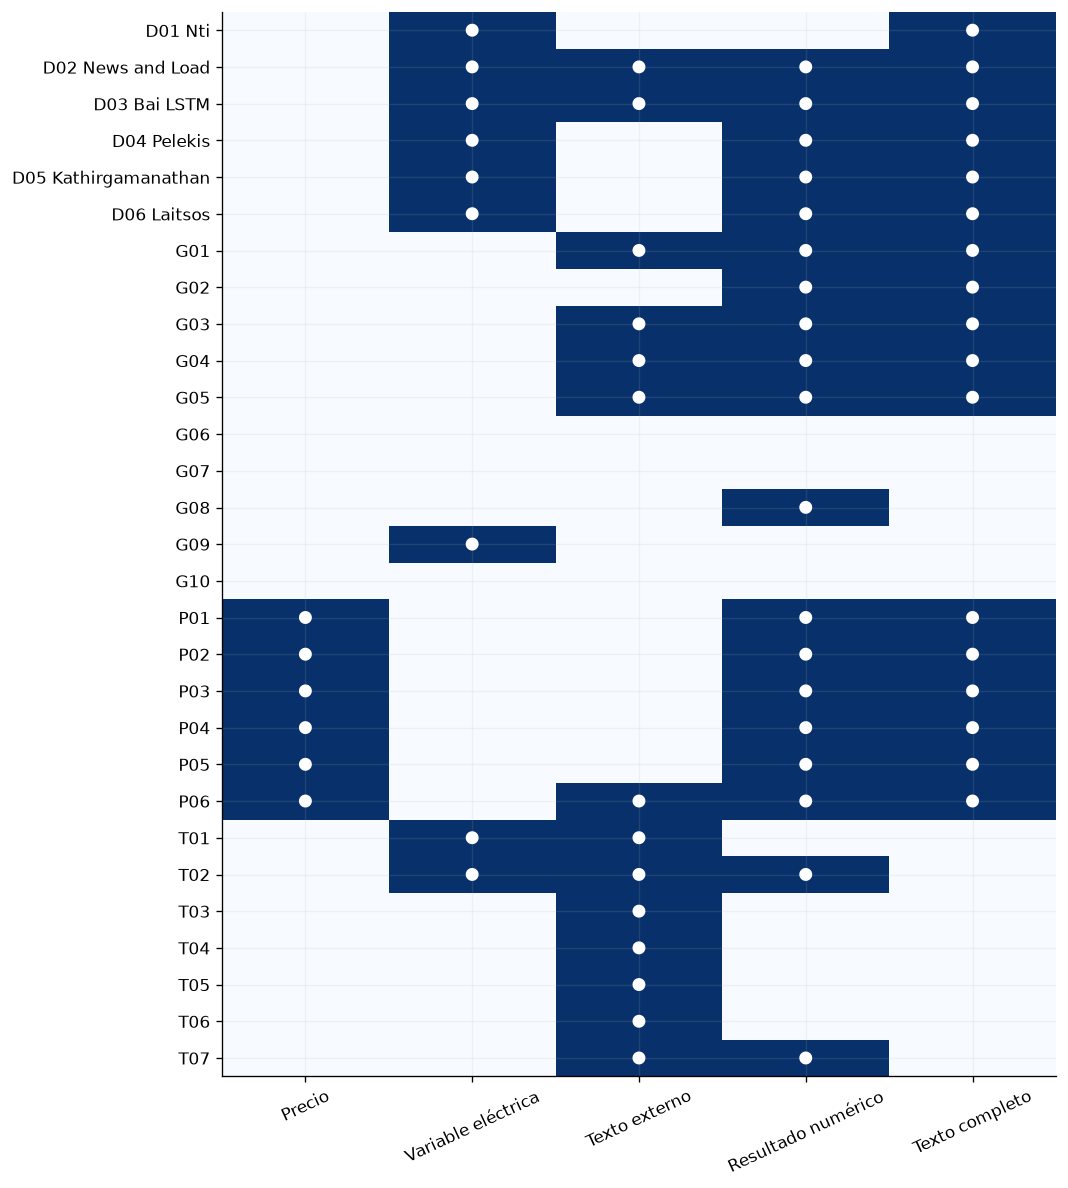

In [3]:
matriz=estudios.set_index('study_id')[['electricity_price','other_electricity_variable','external_text','numeric_result','fulltext_result']].astype(int)
extra=pd.DataFrame([[0,1,0,0,1],[0,1,1,1,1],[0,1,1,1,1],[0,1,0,1,1]],index=['D01 Nti','D02 News and Load','D03 Bai LSTM','D04 Pelekis'],columns=matriz.columns)
extra=pd.concat([extra,pd.DataFrame([[0,1,0,1,1],[0,1,0,1,1]],index=['D05 Kathirgamanathan','D06 Laitsos'],columns=matriz.columns)])
matriz=pd.concat([extra,matriz])
fig,ax=plt.subplots(figsize=(9,10));im=ax.imshow(matriz.values,aspect='auto',cmap='Blues',vmin=0,vmax=1)
ax.set(xticks=range(5),xticklabels=['Precio','Variable eléctrica','Texto externo','Resultado numérico','Texto completo'],yticks=range(len(matriz)),yticklabels=matriz.index)
ax.tick_params(axis='x',rotation=25)
for i in range(len(matriz)):
    for j in range(5):
        if matriz.iloc[i,j]:ax.text(j,i,'●',ha='center',va='center',color='white')
fig.tight_layout();display(fig);plt.close(fig)
textos_completos=int(matriz.fulltext_result.sum()); con_texto=int(matriz.external_text.sum())

De los 29 estudios destacados, 17 cuentan con revisión de texto completo y 14 incorporan texto externo. La matriz separa evidencia sobre variables eléctricas de métodos generales; una alta presencia de texto no prueba su utilidad para demanda. Los identificadores G, P y T remiten a las filas de los CSV y a los estudios de las tablas.

## 8.5. Frecuencia de uso como comparador

La unidad de conteo es el par estudio–familia: varias configuraciones de una familia cuentan una vez. Se incluyen comparadores evaluados y comparadores de benchmarks, excluyendo modelos propuestos, componentes, ablaciones y menciones. MLP y DNN se agrupan; los híbridos conservan su nombre y no se descomponen en familias. Una CNN sin dimensión documentada no se etiqueta automáticamente como CNN1D.

### Evidencia directa de demanda

El denominador contiene cinco estudios empíricos revisados en texto completo: News and Load, Bai con LSTM y Pelekis et al., Kathirgamanathan et al. y Laitsos et al. Nti et al. se excluye por ser revisión; Forwardformer permanece fuera hasta disponer de extracción de texto completo. ExtraTrees no suma una familia neuronal. La convolución utilizada para comprimir noticias tampoco se cuenta como CNN predictora independiente.

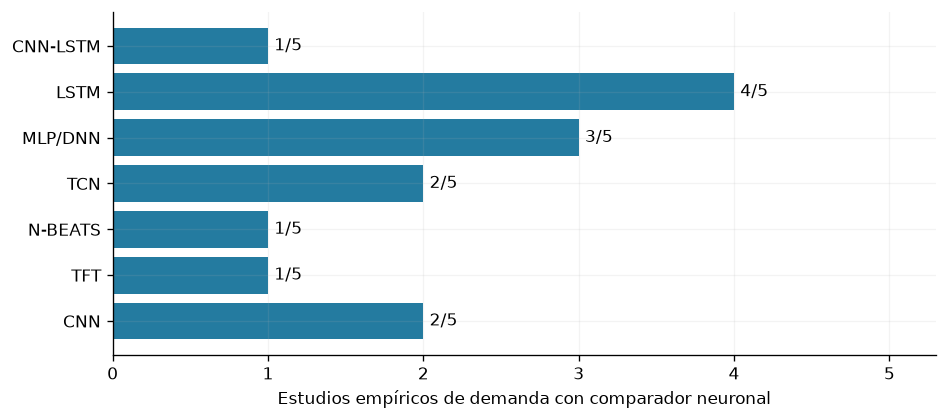

In [4]:
demanda=pd.DataFrame([('News and Load','ExtraTrees'),('Bai LSTM','LSTM'),('Pelekis','MLP/DNN'),('Pelekis','LSTM'),('Pelekis','N-BEATS'),('Pelekis','TCN'),('Pelekis','TFT')],columns=['estudio','familia'])
demanda=pd.concat([demanda,pd.DataFrame([('Kathirgamanathan','MLP/DNN'),('Kathirgamanathan','LSTM'),('Kathirgamanathan','CNN'),('Laitsos','MLP/DNN'),('Laitsos','LSTM'),('Laitsos','CNN'),('Laitsos','TCN'),('Laitsos','CNN-LSTM')],columns=demanda.columns)],ignore_index=True)
familias=['CNN-LSTM','LSTM','MLP/DNN','TCN','N-BEATS','TFT','CNN']
freq_demanda=demanda.drop_duplicates().groupby('familia').estudio.nunique().reindex(familias,fill_value=0)
fig,ax=plt.subplots(figsize=(8,3.6));ax.barh(familias,freq_demanda,color='#247ba0');ax.invert_yaxis()
for i,v in enumerate(freq_demanda):ax.text(v+.04,i,f'{v}/5',va='center')
ax.set(xlim=(0,5.3),xticks=range(6),xlabel='Estudios empíricos de demanda con comparador neuronal')
fig.tight_layout();display(fig);plt.close(fig)

LSTM aparece en cuatro de cinco estudios empíricos; MLP en tres; CNN1D y TCN, en dos cada una. CNN-LSTM, N-BEATS y TFT aparecen una vez. CNN1D queda empatada en la tercera frecuencia del corpus dirigido. Este recuento justifica su uso como comparador documentado de demanda, sin estimar prevalencia universal. Los dos artículos de Bai comparten línea de investigación y sistema eléctrico; cuentan como publicaciones, sin constituir replicaciones independientes entre países. Los ensambles y las ramas de compresión textual no se descomponen como baselines individuales.

### Precio eléctrico: contraste metodológico y sensibilidad

El registro complementario contiene 16 estudios de precio puntual, dos probabilísticos, uno de un mercado relacionado y una revisión. Se conserva el denominador de estudios elegibles aunque alguno no tenga un comparador neuronal. La revisión se excluye del denominador empírico.

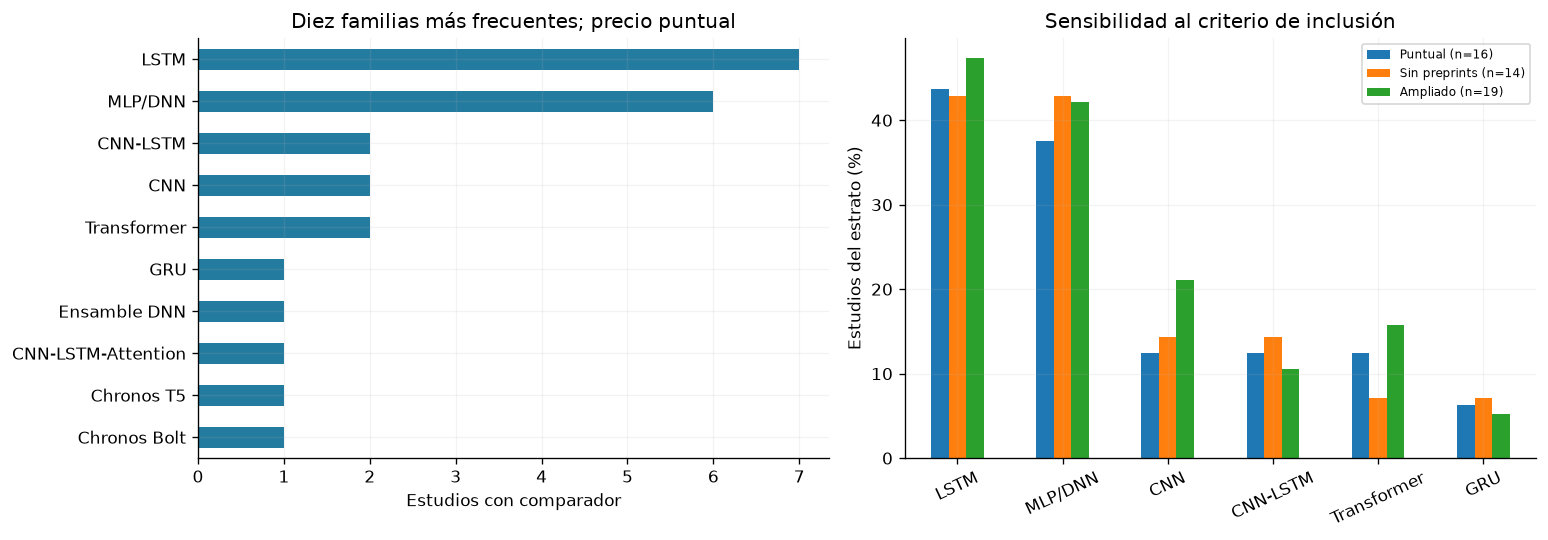

In [5]:
roles=['comparador','comparador_benchmark']
base=extracciones.loc[extracciones.papel.isin(roles)&(extracciones.modelo_neuronal_objetivo==1),['study_id','familia']].drop_duplicates()
assert (extracciones.merge(comparadores[['study_id','sha256']],on='study_id',suffixes=('_extraccion','_estudio')).eval('sha256_extraccion == sha256_estudio')).all()
cohortes={'Puntual (n=16)':set(comparadores.loc[comparadores.estrato=='puntual','study_id']),'Sin preprints (n=14)':set(comparadores.loc[(comparadores.estrato=='puntual')&(comparadores.preprint==0),'study_id']),'Ampliado (n=19)':set(comparadores.loc[comparadores.estrato!='contexto_revision','study_id'])}
frecuencias=pd.DataFrame({nombre:base.loc[base.study_id.isin(ids)].groupby('familia').study_id.nunique() for nombre,ids in cohortes.items()}).fillna(0).astype(int)
verificado=pd.read_csv(D/'frecuencias_verificadas.csv').set_index('familia')
assert frecuencias['Puntual (n=16)'].equals(verificado.estudios_puntuales.reindex(frecuencias.index).rename('Puntual (n=16)'))
orden=frecuencias['Puntual (n=16)'].sort_values(ascending=False,kind='stable').index[:10]
fig,axes=plt.subplots(1,2,figsize=(13,4.6))
frecuencias.loc[orden,'Puntual (n=16)'].sort_values().plot.barh(ax=axes[0],color='#247ba0')
axes[0].set(xlabel='Estudios con comparador',ylabel='',title='Diez familias más frecuentes; precio puntual')
seleccion_f=['LSTM','MLP/DNN','CNN','CNN-LSTM','Transformer','GRU']
porcentajes=frecuencias.loc[seleccion_f].div([len(v) for v in cohortes.values()],axis=1)*100
porcentajes.plot.bar(ax=axes[1],rot=25);axes[1].set(ylabel='Estudios del estrato (%)',xlabel='',title='Sensibilidad al criterio de inclusión');axes[1].legend(fontsize=7)
fig.tight_layout();display(fig);plt.close(fig)

En precio puntual, LSTM aparece en 7/16 estudios y MLP/DNN en 6/16. CNN aparece en 2/16, empatada con CNN-LSTM y Transformer; sólo una de las dos comparaciones CNN identifica explícitamente convolución unidimensional. Al excluir preprints, LSTM pasa a 6/14 y MLP permanece en 6/14. El estrato ampliado cambia el denominador a 19 e incorpora problemas probabilísticos y otro mercado, por lo que funciona como sensibilidad, no como estimación principal para demanda.

El protocolo evita contabilizar GRU de una capa de Ugurlu et al. como baseline porque forma parte de una ablación. Incluirla elevaría GRU de uno a dos estudios puntuales. LSTM-FFEC mantiene su identidad y no se convierte en LSTM simple. Los componentes de descomposición y las ramas de híbridos tampoco se cuentan como modelos independientes.

### Evaluación crítica de los textos completos

| Estudio | Estrato | Datos y protocolo | Limitación registrada |
|---|---|---|---|
| [Lago et al. (2018)](https://jesuslago.com/wp-content/uploads/Lago2018b.pdf) | puntual | Mercado belga day-ahead; salida de 24 horas. Comparación de 27 modelos; recalibración diaria; separación de optimización y evaluación. | DNN, LSTM-DNN, GRU-DNN y CNN son propuestas del artículo: no se cuentan como baselines. El MLP de la literatura sí. Tamaño y datos afectan el ranking. |
| [Lago et al. (2021)](https://jesuslago.com/wp-content/uploads/1-s2.0-S0306261921004529-main-1.pdf) | puntual | Nord Pool, PJM, EPEX BE/FR/DE; 24 salidas. Componente empírico del benchmark; cuatro años de calibración, recalibración diaria y validación para parada/HPO. | Se incluye únicamente el experimento primario; las menciones del review no aportan presencias. Tamaños, activación y regularización se optimizan por mercado; no hay una única DNN universal. |
| [Ugurlu et al. (2018)](https://mdpi-res.com/d_attachment/energies/energies-11-01255/article_deploy/energies-11-01255.pdf) | puntual | Mercado turco day-ahead; ventana móvil de tres años. Comparadores estadísticos y neuronales; una y tres capas; MAE y pruebas DM. | La propuesta es GRU multicapa; GRU de una capa se registra como control de profundidad. CNN F1–4 difiere entre tablas 2 (9.82) y 3 (8.57): se extrae explícitamente tabla 3. La paciencia se comprueba sobre pérdida de entrenamiento. |
| [Kuo y Huang (2018)](https://mdpi-res.com/d_attachment/sustainability/sustainability-10-01280/article_deploy/sustainability-10-01280.pdf) | mercado relacionado | Datos PJM 2017, descritos como regulation market capacity clearing price cada media hora. Diez segmentos; tres meses de entrenamiento y uno de prueba por segmento; normalización y shuffle en flujo. | No se equipara precio de capacidad/regulación con precio spot de energía; sólo sensibilidad ampliada. Arquitecturas de los comparadores insuficientemente especificadas; posibles ambigüedades de procedencia/unidad. |
| [Ghimire et al. (2024; online 2023)](https://burjcdigital.urjc.es/server/api/core/bitstreams/584ad847-68b7-4ef1-b8fb-08db68f8eeee/content) | puntual | Queensland AEMO 2014–octubre 2022; modelos estacionales y anual. Ajuste bayesiano, validación para scheduler; comparación con LSTM,DNN,RF,XGB,VMD-CLSTM y CLSTM. | No hay CNN sola: CLSTM es híbrido. B.12 reporta range(50,50,5) vacío para tercera capa DNN y repite nombre Filter1: se conservan como defectos de especificación. Causalidad de descomposición y recorte de extremos requieren revisión operativa. |
| [Ghimire et al. (2025)](https://opus.lib.uts.edu.au/bitstream/10453/190017/2/1-s2.0-S2666546825000242-main.pdf) | puntual | South Australia y Tasmania, AEMO; media hora. Optuna para modelos; compara referencias simples, híbridas y con STL. | MLP y DNN aportan una sola familia. Tabla 4 especifica CLSTM pero no hace reproducible la CNN sola. Debe verificarse disponibilidad causal de componentes STL/VMD; frecuencia no acredita validez de todas las ganancias publicadas. |
| [Zhang et al. (2023)](https://www.ebi.ac.uk/europepmc/webservices/rest/PMC9938466/fullTextXML) | puntual | España; conjunto público de generación, demanda, clima y precio horario de cuatro años. Proporción train:test:verification 8:1:1; normalización y descomposición descritas por pasos. | Las configuraciones de LSTM/GRU no están detalladas. El orden de normalización y STL necesita comprobar ajuste exclusivo con entrenamiento. TCN y N-BEATS son componentes; TCN-LSTM sí es comparador. |
| [Wang et al. (2026)](https://mdpi-res.com/d_attachment/energies/energies-19-00761/article_deploy/energies-19-00761.pdf) | puntual | PJM; precio horario. Entrenamiento cronológico; compara TCN, CNN-LSTM-Attention y Transformer con ensamble dinámico. | No contiene CNN o LSTM independientes; se conservan separadas la TCN y la arquitectura híbrida. Presupuesto y configuración exacta de cada comparador no completamente reproducibles. |
| [Elashhab et al. (2026), preprint v1](https://arxiv.org/pdf/2608.17091v1) | puntual | DE-LU 2024; entrenamiento desde 2018/2020/2023 según modelo; transferencia entre mercados. Benchmark de seis arquitecturas; MAE, Adam, Optuna; 7 días de entrada y 24 horas de salida. | Preprint: cabecera contiene DOI/fechas de plantilla, no se usan como identificador. Distintos presupuestos y ventanas elegidas por modelo; no se infiere igualdad de recursos. Anchos finales no publicados en la tabla comparativa. |
| [Laitsos et al. (2024)](https://mdpi-res.com/d_attachment/energies/energies-17-01625/article_deploy/energies-17-01625.pdf) | puntual | Precio eléctrico europeo; datos y separación descritos en §3. Compara arquitecturas con atención y ensambles propuestos frente a perceptrón de una capa. | Un perceptrón sin capa oculta no es MLP. CNN-GRU-Attention no acredita CNN o GRU independientes. El estudio aporta cero presencias estrictas a las tres familias, aunque es elegible. |
| [Michalakopoulos et al. (2026)](https://mdpi-res.com/d_attachment/energies/energies-19-00376/article_deploy/energies-19-00376.pdf) | puntual | Grecia, Bélgica e Irlanda; ventanas de 7/14/30/45/60/90 días. Benchmark de ventanas cortas, naive y árboles potenciados. | La tabla abrevia LSTM, pero figura 6 y método especifican LSTM con Feed-Forward Error Correction: se cuenta híbrido. Los mejores modelos dependen del mercado y ventana. |
| [Radziukyniene et al. (2026)](https://mdpi-res.com/d_attachment/applsci/applsci-16-03865/article_deploy/applsci-16-03865.pdf) | puntual | Lituania 2022; alta volatilidad. NN1 recurrente y NN2–6 densas alimentan metarred NN7; comparación de versiones del método. | Las redes densas/recurrentes son componentes; tabla 7 es extensión incremental del mismo ensamble. Tabla 6 compara cifras de otras publicaciones, no baselines reentrenados. |
| [Mubarak et al. (2024)](https://research-repository.griffith.edu.au/server/api/core/bitstreams/f793f553-1e34-4690-ac7a-5822034e7878/content) | puntual | Reino Unido y Alemania; day-ahead. Compara CNN-BiLSTM-AR sin HPO y con RS/GA/PSO. | Controles de optimización del mismo híbrido; la tabla 6 cita métricas ajenas. Ningún resultado aislado de CNN/MLP/LSTM se cuenta. |
| [Wang et al. (2024)](https://mdpi-res.com/d_attachment/energies/energies-17-04885/article_deploy/energies-17-04885.pdf) | puntual | Japón; JEPX, datos meteorológicos y oferta/demanda numéricos. Misma arquitectura CNN-LSTM y diferentes pérdidas; ensamble de inicializaciones. | §3.1 declara que no compara MLP,CNN,RNN o LSTM independientes. La referencia de pérdida MAE es un control del mismo híbrido, no un baseline de sus componentes. |
| [Hornek et al. (2025), preprint v2](https://arxiv.org/pdf/2506.08113v2) | puntual | Austria, Bélgica, Alemania, Francia, Países Bajos; prueba 2024. Precio univariado; entrada una semana; modelos clásicos con 12 semanas de ajuste; foundations preentrenados. | No compara MLP,CNN o LSTM. Los tamaños de un mismo modelo se colapsan. La transformación cuantil se ajusta en train; riesgo de contaminación de preentrenamiento requiere atención. |
| [Lu et al. (2026)](https://mdpi-res.com/d_attachment/energies/energies-19-02438/article_deploy/energies-19-02438.pdf) | probabilístico | Shaanxi, enero y abril 2025; 15 minutos; 2016 puntos por conjunto mensual seleccionado. 1824 train y 192 test; pronósticos por intervalos; PICP/MPIW/AIS. | Sólo dos meses; no equivalente al problema puntual del E1. No se suman ensamble MLP y MLP simple. Configuración exacta de cada baseline no completamente reproducible. |
| [Lipiecki y Weron (2026), preprint v1](https://arxiv.org/pdf/2609.00089v1) | probabilístico | Alemania, España y Polonia, 2021–2025; precios y covariables. Predicciones de distribución, medianas y arbitraje; DDNN-JSU y LEAR+CP como referencias. | DDNN-JSU tiene dos capas densas pero parametriza una distribución Johnson SU: familia separada. Preprint; métricas puntuales no equiparan el entrenamiento distribucional con MLP simple. |
| [Jasiński (2025)](https://mdpi-res.com/d_attachment/energies/energies-18-06422/article_deploy/energies-18-06422.pdf) | revisión | Revisión de publicaciones de precio eléctrico. Fuente secundaria para rastrear referencias, sin repetir sus conteos como observaciones primarias. | Excluida de frecuencias; no es experimento empírico independiente. |
| [Khalid et al. (2020; online 2019)](https://www.ebi.ac.uk/europepmc/webservices/rest/PMC7516403/fullTextXML) | puntual | Demanda y precio horarios; experimentos separados. JLSTM con optimización Jaya frente a LSTM clásico y SVM; horizontes mostrados de semana/mes/trimestre. | Se incluye sólo el resultado de precio. Normalización usa mínimos/máximos del conjunto completo según §3.2.3; partición y arquitectura del comparador insuficientes. RMSE menor que MAE en tabla 1: inconsistentes si misma escala/muestra; cifras se conservan sin reinterpretarlas. |
| [Zamee et al. (2024)](https://opus.lib.uts.edu.au/bitstream/10453/181427/2/Self-Supervised_Adaptive_Learning_Algorithm_for_Multi-Horizon_Electricity_Price_Forecasting.pdf) | puntual | NEPOOL/ISO New England, un año de flujo dentro de fuente 2004–2008; horizontes 1/12/24 h. Selección adaptativa de variables y reentrenamiento; GRNN principal frente a ANN,RNN,LSTM bajo el mismo algoritmo. | La comparación evalúa redes dentro del procedimiento adaptativo. El texto confunde capas con neuronas; regla 2/3 del número de entradas no determina por sí sola la profundidad. No hay CNN. Tabla de tiempos es específica del hardware y no transferible a Colombia. |

Esta valoración resume comparabilidad, disponibilidad y reporte; no es una escala de calidad validada ni sustituye una evaluación independiente.

## 8.6. Arquitecturas de interés y modelos numéricos

MLP, LSTM y CNN1D contrastan representación densa, estado recurrente y filtros temporales; ARX aporta un control lineal regularizado. Pelekis et al. sustenta conservar una referencia densa frente a métodos más complejos. La frecuencia de comparadores complementa esta justificación sin constituir una regla universal de selección.

Las configuraciones seleccionadas utilizan historia de 168 horas, salida de 24 y 23 variables de calendario. MLP contiene dos capas de 128 unidades; LSTM una capa de 48; CNN1D una convolución de 16 filtros y kernel cinco, seguida de promedio local de factor dos y una cabeza lineal. LSTM y CNN1D concatenan calendario futuro a la representación temporal y predicen residuos alrededor del nivel. ARX utiliza 48 rezagos.

Con f=24, L=168, H=24, K=23 y d=L+HK, MLP tiene P=(d+1)u+(u+1)u+(u+1)H; LSTM, P=4u(f+u+2)+(u+HK+1)H; CNN1D, P=(kf+1)c+(Lc/2+HK+1)H. Los costos dominantes por ejemplo son O(du+u²+uH), O(Lu(f+u)+(u+HK)H) y O(Lkfc+(Lc/2+HK)H), respectivamente.

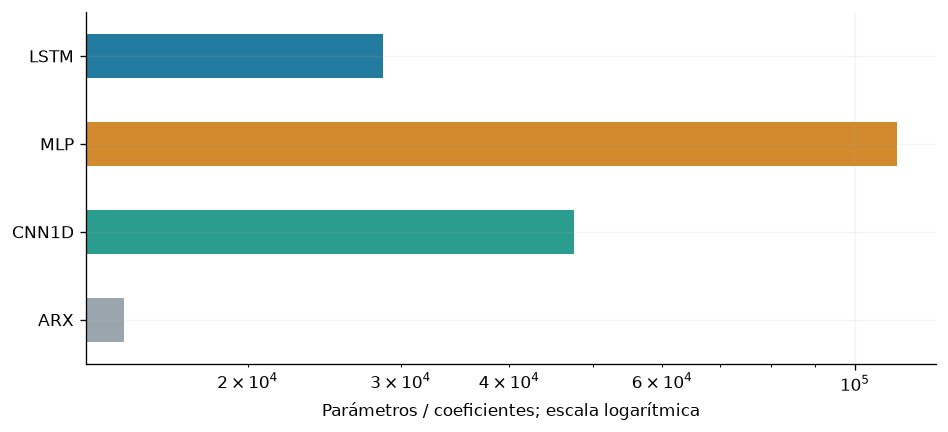

In [6]:
L,H,K,f=168,24,23,24;d=L+H*K;u=128
parametros=pd.Series({'ARX':(48+H*K+1)*H,'CNN1D':(5*f+1)*16+((L//2)*16+H*K+1)*H,'MLP':(d+1)*u+(u+1)*u+(u+1)*H,'LSTM':4*48*(f+48+2)+(48+H*K+1)*H})
assert parametros.to_dict()=={'ARX':14424,'CNN1D':47464,'MLP':111896,'LSTM':28632}
fig,ax=plt.subplots(figsize=(8,3.7));parametros.plot.barh(ax=ax,color=['#9ba5ae','#2a9d8f','#d18a2d','#247ba0']);ax.set_xscale('log');ax.set_xlabel('Parámetros / coeficientes; escala logarítmica');fig.tight_layout();display(fig);plt.close(fig)

La MLP presenta la mayor capacidad parametrizada. La CNN1D conserva una salida densa sobre posiciones temporales agrupadas, por lo que su tamaño no depende sólo del número de filtros. Los parámetros no determinan por sí solos precisión ni latencia; el capítulo de modelos contrasta error, variabilidad y tiempo registrado.

### 8.6.1. MLP sobre ventana de rezagos

La MLP representa interacciones no lineales entre una ventana fija y calendario mediante capas densas. Su sesgo inductivo no impone recurrencia ni invariancia a traslaciones temporales; cada posición puede aprender una función distinta. Es adecuada cuando los perfiles y el calendario explican gran parte de la variación, pero puede depender de una selección suficiente de rezagos y de regularización. Su paralelización es directa y su costo crece con longitud de entrada, ancho y profundidad.

Pelekis et al., Kathirgamanathan et al. y Laitsos et al. incluyen modelos densos como comparadores. Los datasets, DOI, resultados y dispersión disponible están en §8.2; sus configuraciones no son idénticas a las del SIN. La arquitectura seleccionada y su pérdida, optimizador, parámetros y costo se detallan en §10.2. La referencia lineal ARX contrasta si la capacidad no lineal añade precisión bajo las entradas observadas.

### 8.6.2. LSTM sobre secuencias

La LSTM utiliza puertas y estado recurrente para representar dependencias de una secuencia. El último estado comprime la historia, por lo que una memoria más larga no garantiza conservar toda la información relevante. Su capacidad permite relaciones temporales flexibles, pero depende de escalado, longitud de secuencia y regularización. El procesamiento recurrente introduce una dependencia de cálculo entre pasos y puede elevar el tiempo respecto a una red densa de tamaño comparable.

Las comparaciones de demanda de §8.2 documentan LSTM numéricas y variantes con documentos. El uso de texto, los horizontes y el presupuesto difieren entre artículos. No se atribuye una mejora a la recurrencia aislada ni se equipara el error entre sistemas eléctricos. §10.2 reproduce la configuración ejecutada y §10.9 contrasta estabilidad por fechas e inicializaciones.

### 8.6.3. CNN1D sobre historia temporal

La CNN1D comparte filtros entre posiciones y favorece patrones locales. La longitud del kernel, el agrupamiento y la cabeza de salida determinan cuánto contexto puede representar. El entrenamiento permite paralelizar posiciones; la cabeza aplanada del modelo ejecutado conserva dependencias con el tamaño de ventana y puede concentrar una parte importante de los parámetros. La arquitectura no incorpora por sí sola memoria recurrente.

Los dos textos completos incorporados identifican CNN1D como comparador de demanda; sus configuraciones y límites se registran en §8.2. La frecuencia observada empata con TCN en el corpus dirigido, sin justificar que ambas arquitecturas sean intercambiables. TCN conserva su categoría porque añade estructura temporal propia. §10.2 contiene las fórmulas de capacidad y costo de la CNN seleccionada.

### 8.6.4. Comparación crítica de robustez y escalabilidad

| Aspecto | MLP | LSTM | CNN1D |
|---|---|---|---|
| Representación | Ventana fija con pesos por posición. | Estado recurrente que resume la secuencia. | Filtros locales compartidos y cabeza temporal. |
| Sensibilidad a revisar | Rezagos, ancho y representación del calendario. | Escalado, longitud, compresión del estado y regularización. | Kernel, agrupamiento, campo receptivo y dimensión de la cabeza. |
| Escalabilidad esperada | Paralelización densa; capacidad crece con entrada y ancho. | Costo dependiente de secuencia y recurrencia. | Convoluciones paralelizables; cabeza aplanada crece con ventana. |
| Evidencia de robustez | Comparar años, semillas y entradas equivalentes. | Separar variabilidad de inicialización y cambio de régimen. | Examinar conservación de picos y sensibilidad a cambios locales. |

La robustez no puede ordenarse universalmente desde estudios con distintos datos, épocas y búsquedas. El corpus presenta resultados heterogéneos y reporte desigual de repeticiones; una media publicada sin dispersión limita la comparación. Los diagnósticos propios por año, hora, tipo de día, atípicos y permutación de demanda permiten contrastar mecanismos en el SIN, sin demostrar invariancia causal. Las complejidades teóricas tampoco sustituyen la latencia medida: la implementación, el dispositivo y el tamaño del lote condicionan el costo.

### Alcance del cumplimiento bibliográfico

El corpus dirigido incluye cinco estudios empíricos de demanda para el recuento de comparadores y una revisión de contexto. Los doce resúmenes son material contextual y no evidencia elegible para ese recuento. No se recuperaron las cadenas ni las fechas originales de Scopus y Web of Science, no existe un flujo PRISMA conciliado entre todas las bases y no hubo un segundo revisor independiente. Las secciones por modelo y la comparación crítica completan la presentación, pero no convierten la revisión dirigida en una revisión sistemática. Se conservan estas carencias como pendientes de §3.

### Extensiones respaldadas por la revisión

| Línea | Estudios orientadores | Interés para demanda | Condición de evaluación |
|---|---|---|---|
| Multiescala y descomposición | Forwardformer, DDformer, CSConv, TCN, N-BEATS | Representar ciclos, tendencia e interacciones a distintas escalas. | Ajustar transformaciones con historia disponible; comparar con las referencias estacionales. |
| Mezcla y eficiencia | MTS-Mixers, CKVF, LHCnn | Reducir costo de atención y separar mezcla temporal y entre canales. | Medir parámetros, tiempo y error con presupuesto comparable. |
| Texto externo y fusión | News and Load, Bai LSTM, AGESL, BELT, TSITM | Representar eventos, sentimiento, documentos o tópicos mediante fusión temprana o tardía. | Ablación numérica/texto con mismos orígenes, semillas y presupuesto. |
| Representaciones de lenguaje | Time-MMD, REST-TS, TeR-TSF, TimesX, TS-PTLM | Alinear contexto documental y comportamiento temporal, o supervisar residuos. | Separar texto observado, recuperado y generado; registrar cobertura y disponibilidad. |
| Control e incertidumbre | ARX, RSAM, modelos probabilísticos | Contrastar no linealidad y caracterizar incertidumbre del pronóstico. | Distinguir intervalos predictivos de intervalos de incertidumbre de la métrica. |

## 8.7. Síntesis e implicaciones para el experimento

La evidencia directa favorece comparar redes con inductivos diferentes y referencias estacionales antes de incrementar complejidad. No sostiene que una arquitectura domine en todos los países ni que añadir clima o noticias produzca una mejora automática. Los estudios de precio aportan protocolos y alternativas, pero su volatilidad, unidades y mecanismos económicos difieren de los de demanda.

Las mejoras documentales requieren disponibilidad anterior al origen de pronóstico. Vocabularios, selección de atributos, tópicos, normalización y descomposiciones se ajustan dentro de entrenamiento; los documentos con fecha de edición pero sin hora verificable se incorporan desde el día siguiente. Los textos cuya disponibilidad histórica no está verificada conservan esa marca y requieren análisis de sensibilidad. Las revisiones de series y las fechas editoriales limitan la reconstrucción retrospectiva.

La atención o la importancia de una palabra indican asociación dentro del modelo y no causalidad. El deterioro observado en algunas combinaciones de Bai et al. y en algunos casos de REST-TS exige controlar ruido, cobertura y redundancia, además de evaluar ganancias. En NSW-EPNews, una ablación que elimina simultáneamente noticias y temperatura no identifica por sí sola el efecto del texto.

La comparación del proyecto conserva MASE como métrica primaria, margen relativo del 3 %, unidad diaria de 24 errores, α=0,05 y potencia objetivo 0,80. MAE mantiene interpretación en kWh; RMSE caracteriza mayor penalización de extremos. Los valores publicados con métricas diferentes se emplean para comprender sus casos, sin convertirlos a una escala común no observada. La selección y los contrastes siguen la partición temporal y el presupuesto documentados en diseño y modelos.

**Decisión.** Mantener MLP, LSTM y CNN1D como contraste de representaciones densas, recurrentes y convolucionales, junto con ARX y referencias ingenuas. **Impacto.** Permite evaluar capacidad, estacionalidad y costo con resultados ya disponibles. **Riesgo.** El corpus dirigido, la extracción por un revisor, los resultados de otros dominios y la revisión posterior al entrenamiento limitan una justificación basada exclusivamente en frecuencia o en selección prospectiva.

## Brecha de investigación y pregunta contrastable

En el corpus auditado, los estudios con titulares y demanda se concentran en Reino Unido y los benchmarks numéricos utilizan otros sistemas eléctricos. No se identificó en estos estudios una comparación de demanda del SIN colombiano a 24 horas que combine disponibilidad histórica verificable de titulares, control del cambio de cobertura editorial y ablación numérica/documental con los mismos orígenes. La ausencia en este corpus no acredita inexistencia en toda la literatura.

La brecha operativa del proyecto es determinar si el contexto documental disponible antes del origen añade capacidad predictiva al baseline numérico del SIN bajo cambios de régimen. La hipótesis contrastable es una reducción relativa de MASE de al menos el 3 %, acompañada de incertidumbre pareada por bloques, frente al baseline congelado y con presupuesto comparable. La siguiente etapa debe separar utilidad del contenido, cobertura de fuentes y selección de representación mediante ablaciones. Los resultados actuales establecen la referencia numérica y no prueban todavía esa contribución del texto.

Time-MMD, de Liu et al., y NSW-EPNews, de Bi et al., aportan referencias metodológicas para integrar series y documentos; sus resultados no se agregan a la evidencia empírica de demanda. Los doce resúmenes se mantienen como contexto, fuera del denominador de comparadores de texto completo.